# Capacitated Vehicle Routing Problem via Column Generation

## Overview

We solve the CVRP using **column generation**: we iteratively solve a relaxed **Restricted Master Problem (RMP)** and add new feasible vehicle routes (columns) via a **pricing subproblem** until no route with negative reduced cost exists.

The problem has:
- 1 **depot** (node 0) and $N$ **customer nodes** on a 2-D Euclidean plane
- Each vehicle carries at most **Q** customers (each requiring 1 unit of capacity)
- As many vehicles as needed; goal is to **minimize total distance**

---

### Restricted Master Problem (RMP)

Let $R$ be the current column pool (feasible routes). Each route $r \in R$ has cost $c_r$ and indicator $a_{ir} = 1$ if customer $i$ is in route $r$.

$$
\begin{aligned}
\min \quad & \sum_{r \in R} c_r \,\lambda_r \\
\text{s.t.} \quad & \sum_{r \in R} a_{ir}\,\lambda_r \geq 1 & \forall\,i \in \text{Customers} & \quad (\text{dual: } \pi_i) \\
& \lambda_r \geq 0 & \forall\,r \in R
\end{aligned}
$$

### Pricing Subproblem

Find a feasible vehicle route (depot → customers → depot, $|\text{route}| \leq Q$) with **minimum reduced cost**:

$$\bar{c}_r = c_r - \sum_{i \in r} \pi_i \cdot a_{ir}$$

Modeled as a MIP over undirected edges with binary depot-leg variables, degree constraints, capacity constraint, and subtour elimination constraints (SECs). If $\bar{c}_r^* < 0$, add the route to $R$ and re-solve the RMP.

### Column Generation Loop

| Step | Action |
|------|--------|
| **Seed** | Start with one singleton route per customer |
| **Solve RMP** | Solve LP relaxation; extract duals $\pi_i$ |
| **Price** | Solve pricing subproblem; find route with min reduced cost $\bar{c}^*$ |
| **Optimal?** | If $\bar{c}^* \geq 0$ → **LP optimal**, stop column generation |
| **Add** | Append new route to $R$; go to Solve |
| **MIP** | Fix column pool; solve integer set-partitioning MIP for final solution |

In [1]:
# ── Dependencies ──────────────────────────────────────────────────────────────
# pip install pyomo highspy numpy matplotlib  (or: poetry install)
%load_ext autoreload
%autoreload 2

import numpy as np
import time
import warnings
warnings.filterwarnings('ignore')

import pyomo.environ as pyo

try:
    import highspy
except ImportError:
    raise ImportError("Install highspy:  pip install highspy")

try:
    solver_test = pyo.SolverFactory('appsi_highs')
    print(f"Pyomo appsi_highs solver available: {solver_test.available()}")
except Exception as e:
    raise ImportError(f"Pyomo appsi_highs not available: {e}")

from helpers import euclidean_distance_matrix, plot_iteration_grid
from vrp_helpers import (
    route_cost, is_feasible, build_rmp, solve_rmp,
    build_pricing_subproblem, extract_route_from_pricing,
    plot_instance, plot_cg_iteration, plot_final_solution, plot_convergence,
)

Pyomo appsi_highs solver available: True


## 1. Problem Instance

We place $N$ **customers** and **1 depot** (node 0) uniformly at random in a $[0,100]^2$ square. The depot is fixed at the center $(50, 50)$. Each customer requires exactly **1 unit** of capacity; each vehicle can carry at most **Q** customers.

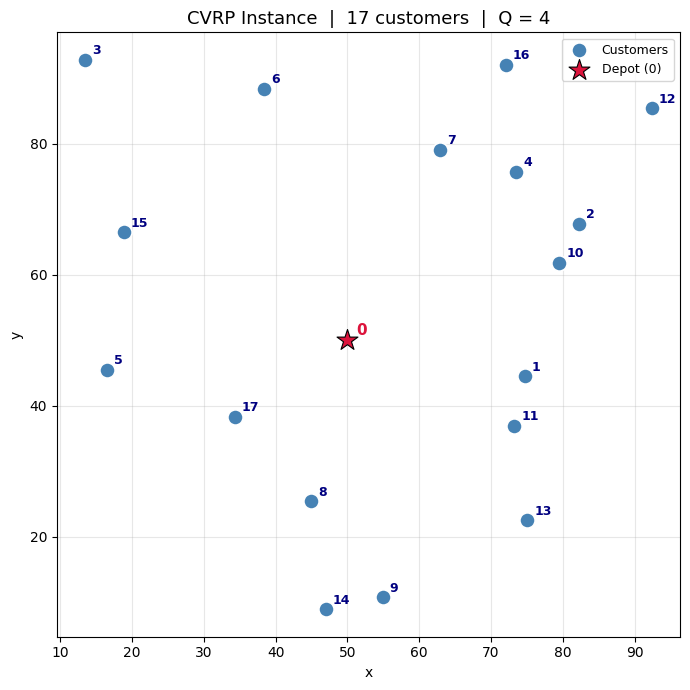

Nodes: 18  (depot + 17 customers)   |   Capacity Q = 4


In [2]:
# ── Problem parameters ────────────────────────────────────────────────────────
DEPOT       = 0
N_CUSTOMERS = 17
Q           = 4          # vehicle capacity (number of customers per vehicle)
N_NODES     = N_CUSTOMERS + 1   # depot + customers

CUSTOMERS = list(range(1, N_NODES))   # node indices 1..N_CUSTOMERS

# ── Random instance ───────────────────────────────────────────────────────────
rng = np.random.default_rng(seed=42)

coords = np.empty((N_NODES, 2))
coords[DEPOT]    = [50.0, 50.0]                          # depot at center
coords[CUSTOMERS] = rng.uniform(5, 95, size=(N_CUSTOMERS, 2))  # customers

D = euclidean_distance_matrix(coords)            # symmetric

plot_instance(coords, DEPOT, CUSTOMERS, Q)
print(f"Nodes: {N_NODES}  (depot + {N_CUSTOMERS} customers)   |   Capacity Q = {Q}")

## 2. Route Representation and Initial Columns

A **route** is a list of customer nodes visited in order. The full path starts and ends at the depot:

$$\text{0} \to c_1 \to c_2 \to \cdots \to c_k \to \text{0}, \qquad k \leq Q$$

We seed the column pool with **singleton routes** (one customer each) — these are trivially feasible and guarantee the RMP has an initial feasible solution.

*Implementation:* `route_cost` and `is_feasible` in [`vrp_helpers.py`](vrp_helpers.py).

In [3]:
# ── Seed the column pool with one singleton route per customer ────────────────
initial_routes: list[list[int]] = [[c] for c in CUSTOMERS]
initial_costs:  list[float]     = [route_cost(r, D, DEPOT) for r in initial_routes]

print(f"Initial column pool: {len(initial_routes)} singleton routes")
print(f"Example: route {initial_routes[0]}  cost = {initial_costs[0]:.2f}")
print(f"Min cost singleton: {min(initial_costs):.2f}  |  Max: {max(initial_costs):.2f}")

Initial column pool: 17 singleton routes
Example: route [1]  cost = 50.52
Min cost singleton: 39.07  |  Max: 112.54


## 3. Restricted Master Problem (RMP)

The RMP is formulated as an **LP relaxation** of a set-covering problem. We solve it to obtain **dual variables** $\pi_i$ for each coverage constraint, which feed the pricing subproblem.

$$
\begin{aligned}
\min \quad & \sum_{r \in R} c_r \,\lambda_r \\
\text{s.t.} \quad & \sum_{r \in R} a_{ir}\,\lambda_r \geq 1 \qquad \forall\, i \in \text{Customers} \quad (\pi_i \geq 0) \\
& \lambda_r \geq 0 \qquad \forall\,r \in R
\end{aligned}
$$

The dual $\pi_i$ measures how much the objective would improve (per unit) if we relaxed the coverage requirement for customer $i$. These shadow prices guide the pricing subproblem to find routes that are "cheapest once credit for serving customers is applied".

*Implementation:* `build_rmp` and `solve_rmp` in [`vrp_helpers.py`](vrp_helpers.py).

## 4. Pricing Subproblem

The pricing subproblem finds a vehicle route (depot — customers — depot, $\leq Q$ customers) with **minimum reduced cost**, modeled as a MIP over undirected edges.

$$\bar{c}_r = \underbrace{\sum_{\{i,j\} \in r} d_{ij}}_{\text{travel cost}} - \underbrace{\sum_{i \in r} \pi_i}_{\text{dual credit}}$$

### Formulation

Let $E_c = \{\{i,j\} : i < j,\; i,j \in C\}$ be the set of undirected customer–customer edges.

**Variables:**
- $x^\text{out}_j \in \{0,1\}$ — 1 if the route **departs** the depot to customer $j$ first (outbound depot leg)
- $x^\text{in}_j \in \{0,1\}$ — 1 if the route **returns** to the depot from customer $j$ last (inbound depot leg)
- $x^c_{ij} \in \{0,1\}$ — undirected customer–customer edge $\{i,j\}$, $i < j$
- $v_i \in \{0,1\}$ — 1 if customer $i$ is visited

Using two separate binary variables for the depot legs makes the out-and-back cost explicit: for a singleton route, $x^\text{out}_j = x^\text{in}_j = 1$ so its depot-leg cost is $2\,d_{0j}$; for a multi-customer route, $x^\text{out}_{j_1}=1$ and $x^\text{in}_{j_k}=1$ for distinct endpoints $j_1 \neq j_k$.

**Objective:**
$$\min \sum_{j \in C} d_{0j}\,(x^\text{out}_j + x^\text{in}_j) + \sum_{\{i,j\}\in E_c} d_{ij}\,x^c_{ij} - \sum_{i \in C} \pi_i\,v_i$$

**Constraints:**
1. $\sum_{j \in C} x^\text{out}_j = 1$ and $\sum_{j \in C} x^\text{in}_j = 1$ — depart and return depot exactly once
2. $(x^\text{out}_i + x^\text{in}_i) + \!\!\sum_{\{i,j\}\in E_c}\!\! x^c_{ij} = 2\,v_i \quad \forall\, i \in C$ — visited customers have degree 2
3. $\sum_{i \in C} v_i \leq Q$ — vehicle capacity
4. $\displaystyle\sum_{\{i,j\}\subseteq S,\,\{i,j\}\in E_c} x^c_{ij} \leq |S|-1 \quad \forall\,S\subseteq C,\;3\leq|S|\leq Q$ — subtour elimination (SECs)

*Implementation:* `build_pricing_subproblem` and `extract_route_from_pricing` in [`vrp_helpers.py`](vrp_helpers.py).

## 5. Visualization Helpers

`plot_cg_iteration`, `plot_final_solution` and `plot_convergence` live in [`vrp_helpers.py`](vrp_helpers.py); `plot_iteration_grid` lives in [`helpers.py`](helpers.py).

## 6. Column Generation Loop

We iterate the RMP–Pricing cycle until the pricing subproblem can no longer find a route with negative reduced cost, which certifies LP optimality of the full master problem.

In [4]:
# ── Solver configuration ──────────────────────────────────────────────────────
lp_solver  = pyo.SolverFactory('appsi_highs')
lp_solver.options['log_to_console'] = False
lp_solver.options['presolve']       = 'on'

mip_solver = pyo.SolverFactory('appsi_highs')
mip_solver.options['log_to_console'] = False
mip_solver.options['mip_rel_gap']    = 1e-3

# ── Initialize column pool ────────────────────────────────────────────────────
routes: list[list[int]]  = [r.copy() for r in initial_routes]
costs:  list[float]      = initial_costs.copy()
history: list[dict]      = []

EPSILON  = 1e-3    # reduced-cost tolerance
MAX_ITER = 150

t_start  = time.perf_counter()

print(f"{'Iter':>5}  {'RMP LP obj':>12}  {'New route':>25}  {'Red. cost':>10}  {'Pool':>5}  {'Time(s)':>8}")
print("─" * 75)

for iteration in range(1, MAX_ITER + 1):

    # ── Solve LP relaxation of RMP ────────────────────────────────────────────
    rmp = build_rmp(routes, costs, CUSTOMERS)
    rmp_obj, duals = solve_rmp(rmp, lp_solver)

    # Extract current λ values
    lambdas = [pyo.value(rmp.lam[r]) for r in range(len(routes))]

    # ── Solve pricing subproblem ──────────────────────────────────────────────
    pricing = build_pricing_subproblem(D, duals, CUSTOMERS, DEPOT, Q)
    mip_solver.solve(pricing)

    reduced_cost = pyo.value(pricing.obj)
    new_route    = extract_route_from_pricing(pricing, DEPOT, CUSTOMERS)

    elapsed = time.perf_counter() - t_start

    # ── Record history ────────────────────────────────────────────────────────
    history.append({
        "iteration":   iteration,
        "rmp_obj":     rmp_obj,
        "duals":       duals.copy(),
        "reduced_cost": reduced_cost,
        "new_route":   new_route.copy() if new_route else [],
        "lambdas":     lambdas.copy(),
        "routes":      [r.copy() for r in routes],   # snapshot before adding
        "pool_size":   len(routes),
    })

    route_str = str(new_route[:6]) + ('...' if len(new_route) > 6 else '')
    print(f"{iteration:>5}  {rmp_obj:>12.4f}  {route_str:>25}  {reduced_cost:>10.4f}"
          f"  {len(routes):>5}  {elapsed:>8.3f}")

    # ── Termination check: no improving column ────────────────────────────────
    if reduced_cost >= -EPSILON:
        print(f"\n✓ Column generation converged after {iteration} iteration(s).")
        print(f"  LP lower bound  : {rmp_obj:.4f}")
        print(f"  Routes in pool  : {len(routes)}")
        print(f"  Wall time       : {elapsed:.3f}s")
        break

    # ── Add new column to pool ────────────────────────────────────────────────
    if not new_route:
        print("Warning: pricing returned empty route with negative rc — stopping.")
        break

    existing_sets = [frozenset(r) for r in routes]
    if frozenset(new_route) in existing_sets:
        print("Warning: pricing returned a duplicate route — stopping.")
        break

    routes.append(new_route)
    costs.append(route_cost(new_route, D, DEPOT))

else:
    print(f"Warning: reached maximum iterations ({MAX_ITER}) without convergence.")

 Iter    RMP LP obj                  New route   Red. cost   Pool   Time(s)
───────────────────────────────────────────────────────────────────────────


    1     1235.5886             [4, 16, 12, 2]   -218.9684     17     0.577


    2     1016.6201              [6, 3, 15, 5]   -183.6156     18     1.322


    3      833.0045             [8, 14, 9, 13]   -175.6361     19     1.841


    4      657.3684             [1, 10, 12, 7]   -156.0889     20     2.414


    5      611.6682              [7, 4, 2, 10]   -163.9315     21     2.963


... (42 outputs left out)

   48      506.2560             [11, 1, 10, 2]     -7.1899     64    81.659


   49      506.0169            [10, 2, 12, 16]     -4.8497     65    85.657


   50      504.8045             [7, 16, 4, 10]     -1.3296     66    92.689


   51      504.8045              [5, 15, 3, 6]     -0.0000     67    96.227

✓ Column generation converged after 51 iteration(s).
  LP lower bound  : 504.8045
  Routes in pool  : 67
  Wall time       : 96.227s


## 7. Integer Solution via MIP

After column generation converges, we freeze the column pool and solve a **set-partitioning MIP** with binary $\lambda_r \in \{0,1\}$. The coverage constraints are tightened to **equality** (each customer served by exactly one vehicle) to get an integer feasible VRP solution.

In [5]:
# ── Build final set-partitioning MIP ─────────────────────────────────────────
final_model = pyo.ConcreteModel(name="VRP_Final_MIP")
R_final = list(range(len(routes)))

final_model.lam = pyo.Var(R_final, domain=pyo.Binary)

final_model.obj = pyo.Objective(
    expr=sum(costs[r] * final_model.lam[r] for r in R_final),
    sense=pyo.minimize,
)

# Equality coverage: each customer served exactly once
final_model.cover = pyo.ConstraintList()
for i in CUSTOMERS:
    final_model.cover.add(
        sum(final_model.lam[r] for r in R_final if i in routes[r]) == 1
    )

# ── Solve ─────────────────────────────────────────────────────────────────────
result_mip = mip_solver.solve(final_model)
elapsed_total = time.perf_counter() - t_start

mip_obj  = pyo.value(final_model.obj)
lam_vals = [pyo.value(final_model.lam[r]) for r in R_final]

selected_routes = [routes[r] for r in R_final if lam_vals[r] > 0.5]
n_vehicles      = len(selected_routes)

print(f"MIP Status: {result_mip.solver.termination_condition}")
print(f"\nFinal integer solution:")
print(f"  Total distance : {mip_obj:.4f}")
print(f"  Vehicles used  : {n_vehicles}")
print(f"  Total time     : {elapsed_total:.3f}s")
print(f"\nRoutes selected:")
for v, route in enumerate(selected_routes, 1):
    print(f"  Vehicle {v:2d}:  cost={route_cost(route, D, DEPOT):.2f}")

MIP Status: optimal

Final integer solution:
  Total distance : 517.4521
  Vehicles used  : 5
  Total time     : 96.548s

Routes selected:
  Vehicle  1:  cost=39.07
  Vehicle  2:  cost=147.13
  Vehicle  3:  cost=110.34
  Vehicle  4:  cost=125.13
  Vehicle  5:  cost=95.78


## 8. Iteration Visualization

Each panel shows the **RMP LP solution** at that iteration — routes with $\lambda > 0$ are drawn (width ∝ $\lambda$) — plus the **new route** (dashed red) entering from the pricing subproblem.

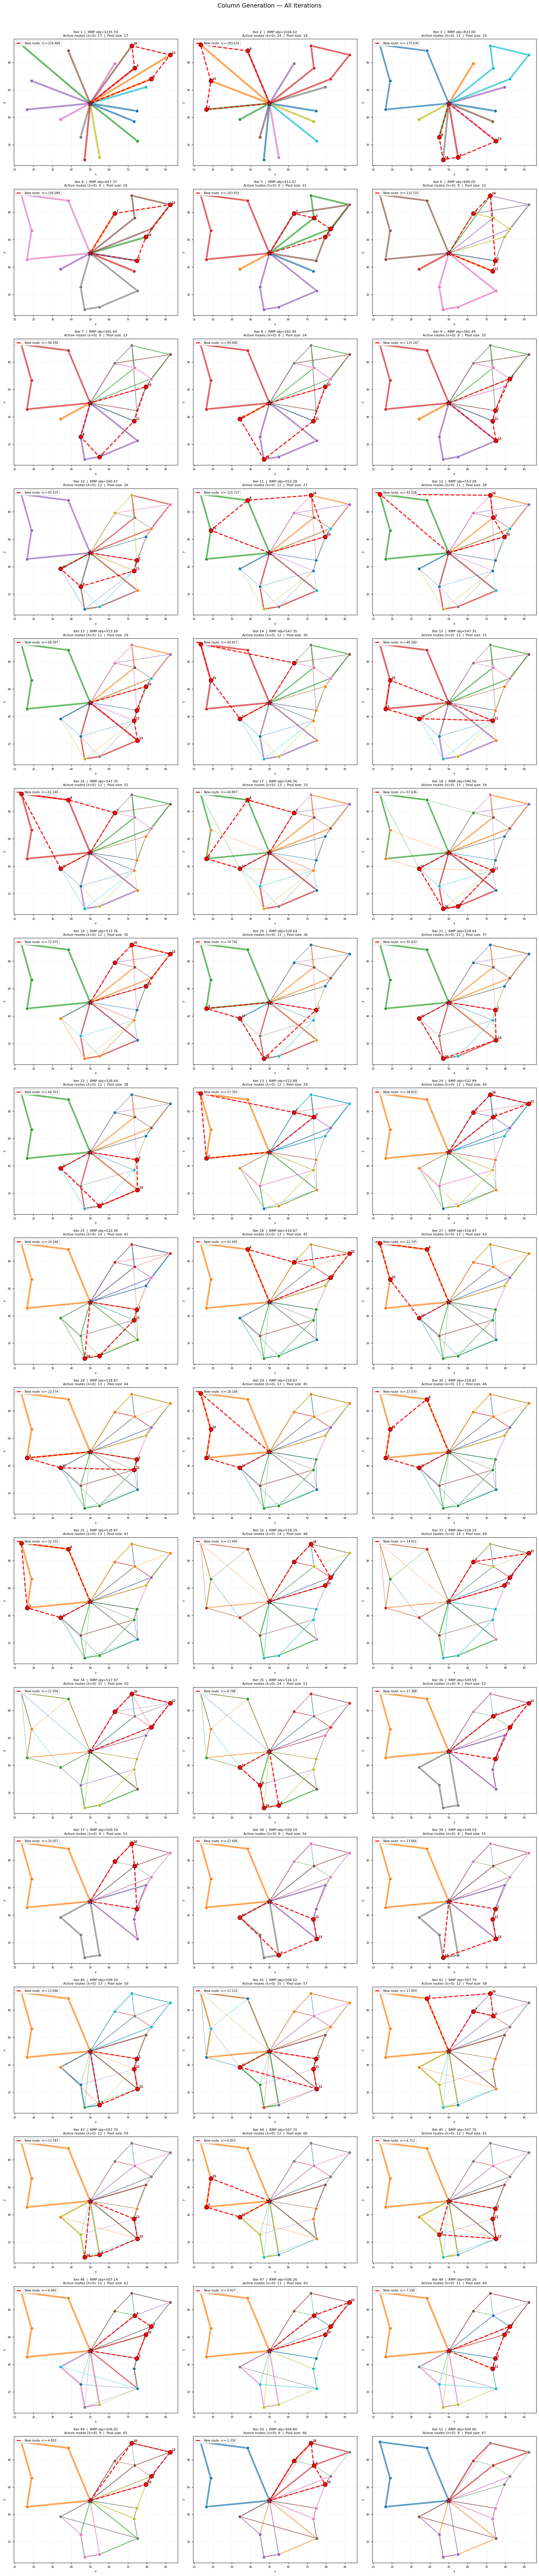

In [6]:
# ── Plot all CG iterations in a 3-column grid ─────────────────────────────────
plot_iteration_grid(
    history,
    lambda h, ax: plot_cg_iteration(
        coords     = coords,
        routes     = h["routes"],
        lambdas    = h["lambdas"],
        new_route  = h["new_route"] if h["reduced_cost"] < -EPSILON else None,
        new_rc     = h["reduced_cost"],
        iteration  = h["iteration"],
        rmp_obj    = h["rmp_obj"],
        depot      = DEPOT,
        ax         = ax,
    ),
    title="Column Generation — All Iterations",
)

## 9. Final Solution Visualization

The optimal integer solution: each vehicle route is colored distinctly, the depot is marked with a star, and the legend lists the route composition and cost.

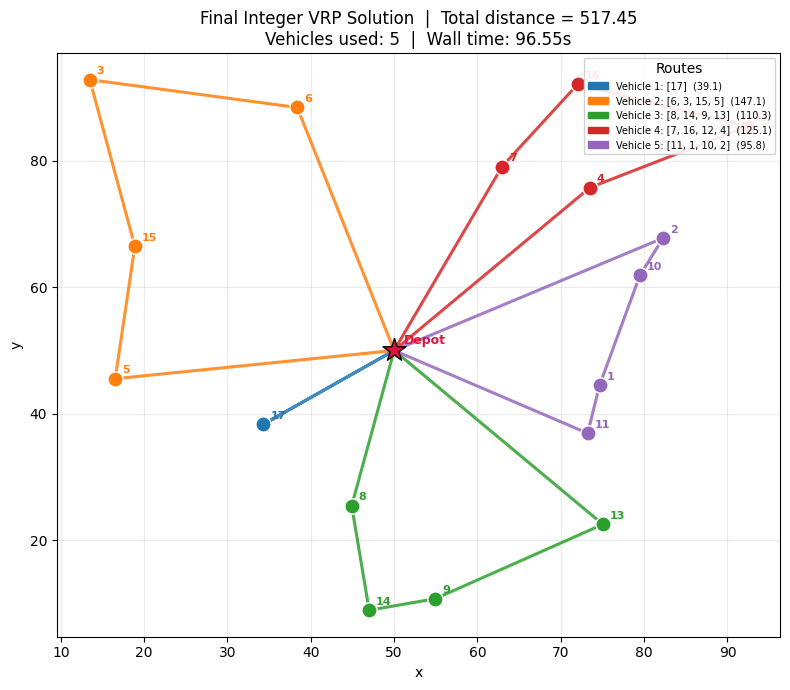

In [7]:
plot_final_solution(
    coords   = coords,
    D        = D,
    routes   = routes,
    lambdas  = lam_vals,
    obj_val  = mip_obj,
    depot    = DEPOT,
    elapsed  = elapsed_total,
)

## 10. Convergence Analysis

Three charts summarize how the column generation procedure converged:

1. **RMP LP objective** — decreases monotonically as better routes enter
2. **Reduced cost of the entering column** — approaches 0 from below at termination  
3. **Cumulative column pool size** — grows by one column per iteration

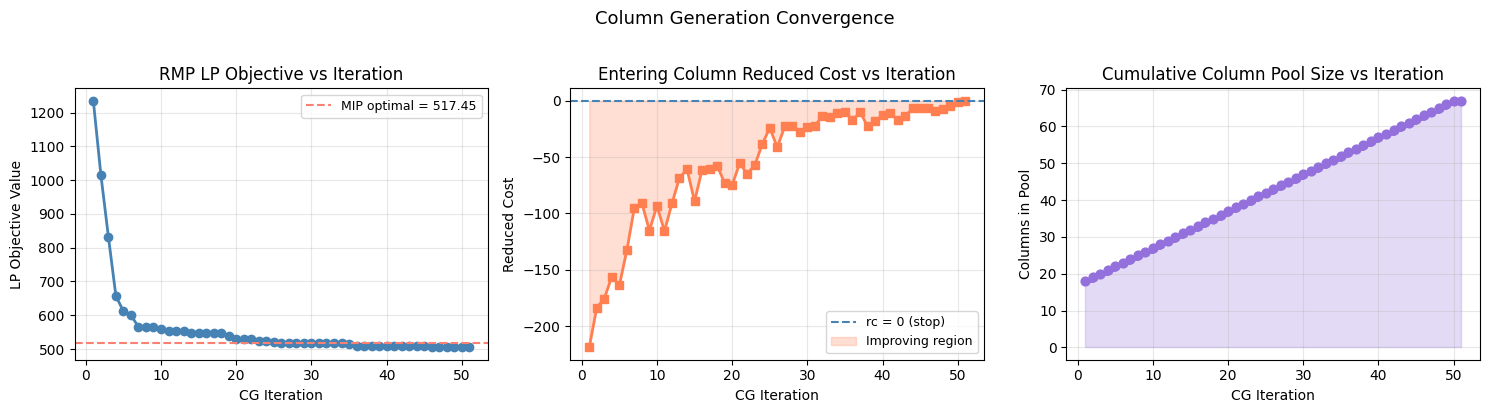


Summary:
  CG iterations       : 51
  Final LP bound      : 504.8045
  Integer solution    : 517.4521
  Integrality gap     : 2.51%
  Columns generated   : 50  (beyond initial singletons)
  Vehicles deployed   : 5
  Customers served    : 17


In [8]:
plot_convergence(history, mip_obj, EPSILON)

lp_bound = history[-1]["rmp_obj"]
print(f"\nSummary:")
print(f"  CG iterations       : {len(history)}")
print(f"  Final LP bound      : {lp_bound:.4f}")
print(f"  Integer solution    : {mip_obj:.4f}")
print(f"  Integrality gap     : {(mip_obj - lp_bound) / lp_bound * 100:.2f}%")
print(f"  Columns generated   : {len(routes) - N_CUSTOMERS}  (beyond initial singletons)")
print(f"  Vehicles deployed   : {n_vehicles}")
print(f"  Customers served    : {sum(len(r) for r in selected_routes)}")